# Custom Geometry Template Tutorial: Elliptical Nanohole Array & 3-Plane Field Maps (`xy`, `xz`, `yz`)

## Physical Motivation & Learning Objectives
Custom unit-cell geometries allow researchers to design arbitrarily shaped metasurfaces. In this tutorial:
1. We demonstrate how to set up custom parameter-driven geometries.
2. We simulate an array of tilted elliptical apertures in a gold film under circular polarization.
3. We plot the Circular Dichroism spectrum and reconstruct local electromagnetic fields ($|\mathbf{E}|^2$ and $|\mathbf{H}|^2$) across **all three orthogonal planes** (`xy`, `xz`, `yz`) with boundaries overlaid.

> [!NOTE]
> **Meshing Workflow: Native Netgen CSG (`examples_netgen/`)**
> Demonstrates custom geometry modeling using Python Netgen CSG via `geo_file='ellipse_msh_template.py'`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## 1. Parameters & Circular Polarization Sweeps


In [2]:
period = 600.0   # nm
r1 = 180.0       # Semi-major axis (nm)
r2 = 90.0        # Semi-minor axis (nm)

wavelengths = np.linspace(600, 950, 6)
light_rcp = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]
light_lcp = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.5), loss=False)

nanohole_layer = objects.NanoStruct(
    '2D_array',
    height_nm=100.0,
    inclusion_a=materials.Air,
    background=materials.Au,
    loss=True,
    geo_file='ellipse_msh_template.py',
    geo_params={'period': period, 'r1': r1, 'r2': r2, 'rot': 30.0, 'lc': 0.15, 'lc2': 3.0},
    plotting_fields=False,
    plt_msh=False
)

def simulate_rcp(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nh  = nanohole_layer.calc_modes(light, num_BMs=14)
    stk = Stack((sim_sub, sim_nh, sim_sup))
    stk.calc_scat(pol='R Circ')
    return stk

def simulate_lcp(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nh  = nanohole_layer.calc_modes(light, num_BMs=14)
    stk = Stack((sim_sub, sim_nh, sim_sup))
    stk.calc_scat(pol='L Circ')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_rcp = list(executor.map(simulate_rcp, light_rcp))
    stacks_lcp = list(executor.map(simulate_lcp, light_lcp))

t_rcp = np.array([float(s.t_list[-1]) for s in stacks_rcp])
t_lcp = np.array([float(s.t_list[-1]) for s in stacks_lcp])
cd = t_rcp - t_lcp
res_idx = int(np.argmax(np.abs(cd)))
res_wl = wavelengths[res_idx]

print(f"Peak CD detected at λ = {res_wl:.1f} nm with |CD| = {abs(cd[res_idx])*100:.2f}%.")


Peak CD detected at λ = 670.0 nm with |CD| = 1.04%.


## 2. Transmission and Circular Dichroism Spectra


<ipython-input-1-36901f489bc3>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


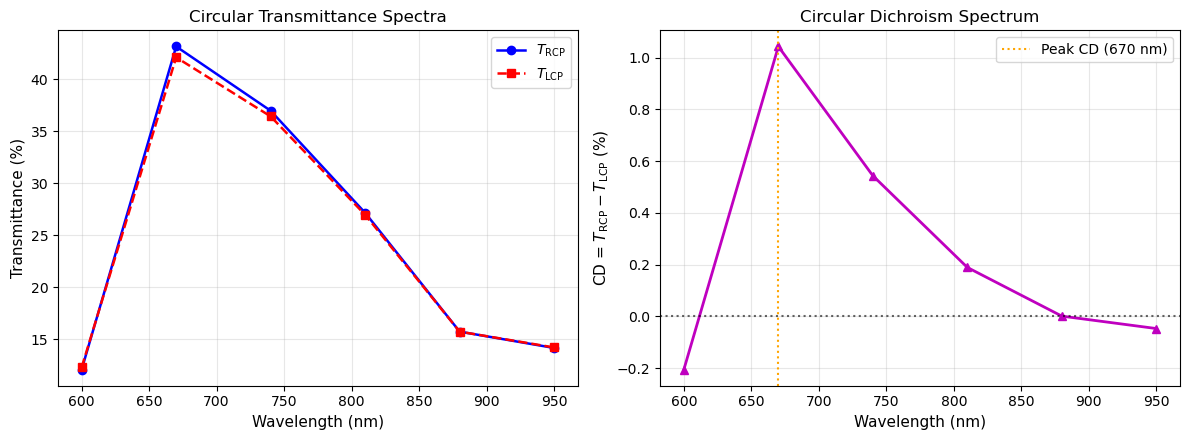

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
ax1.plot(wavelengths, t_rcp * 100, 'b-o', lw=1.8, label=r'$T_{\mathrm{RCP}}$')
ax1.plot(wavelengths, t_lcp * 100, 'r--s', lw=1.8, label=r'$T_{\mathrm{LCP}}$')
ax1.set_xlabel('Wavelength (nm)', fontsize=11)
ax1.set_ylabel('Transmittance (%)', fontsize=11)
ax1.set_title('Circular Transmittance Spectra', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(wavelengths, cd * 100, 'm-^', lw=2)
ax2.axhline(0, color='k', linestyle=':', alpha=0.6)
ax2.axvline(res_wl, color='orange', linestyle=':', lw=1.5, label=f'Peak CD ({res_wl:.0f} nm)')
ax2.set_xlabel('Wavelength (nm)', fontsize=11)
ax2.set_ylabel(r'CD = $T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$ (%)', fontsize=11)
ax2.set_title('Circular Dichroism Spectrum', fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Orthogonal 3-Plane Local Field Maps (`xy`, `xz`, `yz`) at Peak CD Resonance


<ipython-input-1-8807087fe9c0>:92: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


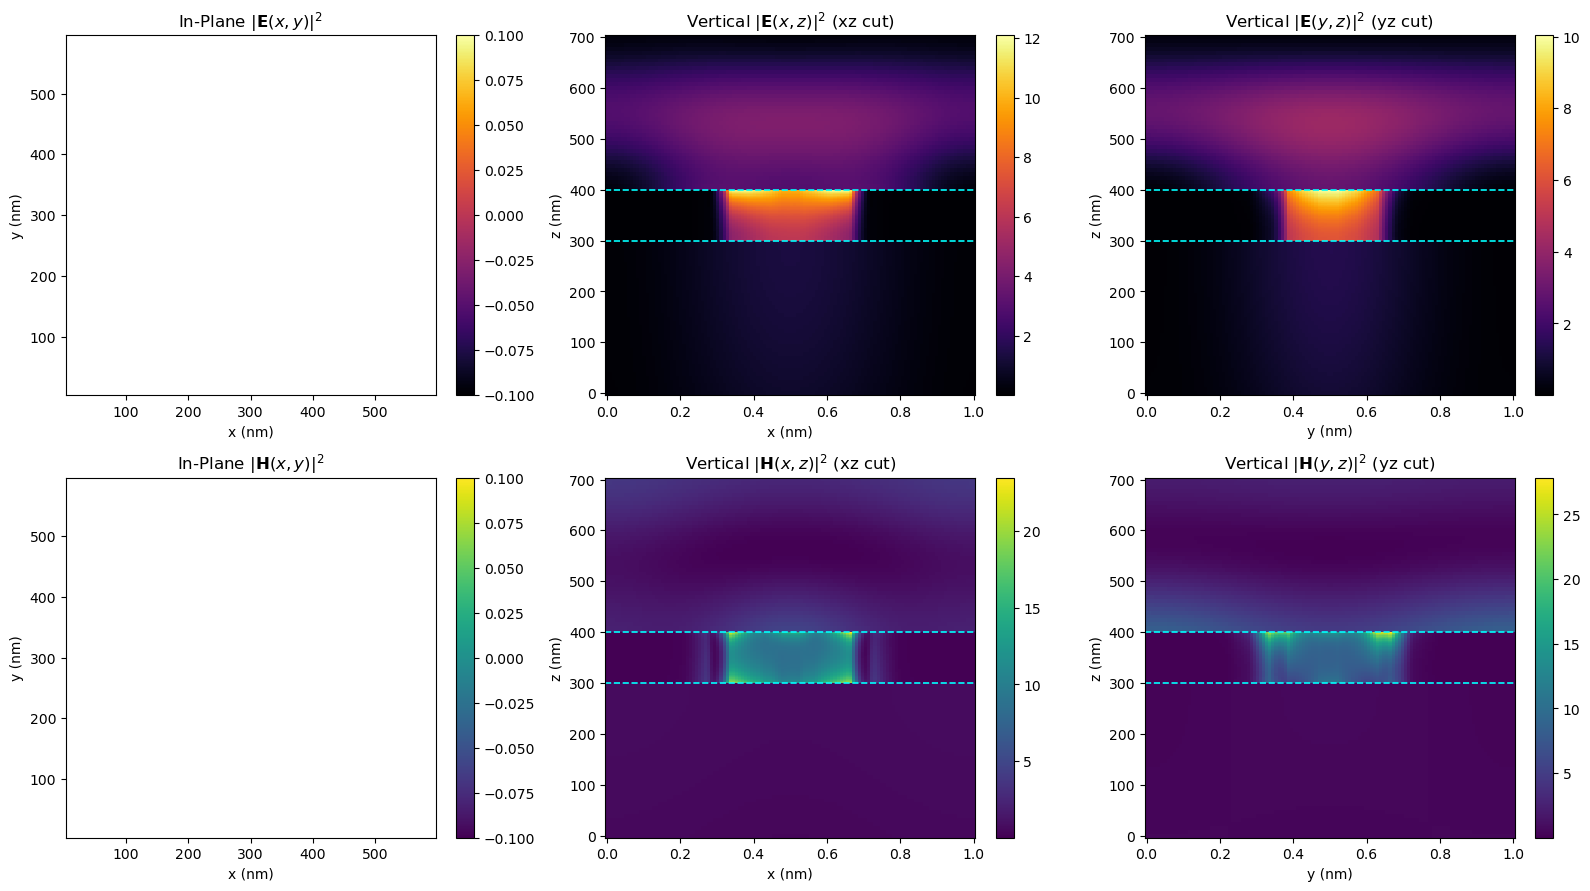

In [4]:
light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)
nanohole_res = objects.NanoStruct(
    '2D_array',
    height_nm=100.0,
    inclusion_a=materials.Air,
    background=materials.Au,
    loss=True,
    geo_file='ellipse_msh_template.py',
    geo_params={'period': period, 'r1': r1, 'r2': r2, 'rot': 30.0, 'lc': 0.15, 'lc2': 3.0},
    plotting_fields=True,
    plt_msh=False
)

sim_sup_res = superstrate.calc_modes(light_res)
sim_sub_res = substrate.calc_modes(light_res)
sim_nh_res  = nanohole_res.calc_modes(light_res, num_BMs=14)
stk_res = Stack((sim_sub_res, sim_nh_res, sim_sup_res))
stk_res.calc_scat(pol='R Circ')

bundle_xy = plotting.fields_interpolator_in_plane(stk_res, lay_interest=1, z_value=50.0, return_H=True)
bundle_xz = plotting.fields_interpolator_cross_section(stk_res, plane='xz', slice_coord=0.5, n_horiz=120, n_vert_per_layer=40, return_H=True)
bundle_yz = plotting.fields_interpolator_cross_section(stk_res, plane='yz', slice_coord=0.5, n_horiz=120, n_vert_per_layer=40, return_H=True)

# Grid evaluation
xg = np.linspace(0.01, 0.99, 120) * period
yg = np.linspace(0.01, 0.99, 120) * period
X_xy, Y_xy = np.meshgrid(xg, yg)

X_xz, Z_xz = np.meshgrid(bundle_xz.u_grid, bundle_xz.v_grid, indexing='ij')
Y_yz, Z_yz = np.meshgrid(bundle_yz.u_grid, bundle_yz.v_grid, indexing='ij')

E2_xy = bundle_xy.AbsE(X_xy, Y_xy)**2
H2_xy = bundle_xy.AbsH(X_xy, Y_xy)**2

E2_xz = bundle_xz.AbsE(X_xz, Z_xz)**2
H2_xz = bundle_xz.AbsH(X_xz, Z_xz)**2

E2_yz = bundle_yz.AbsE(Y_yz, Z_yz)**2
H2_yz = bundle_yz.AbsH(Y_yz, Z_yz)**2

# Tilted ellipse outline for xy
t = np.linspace(0, 2*np.pi, 200)
rot = np.radians(30.0)
x_ell = period / 2.0 + r1 * np.cos(t) * np.cos(rot) - r2 * np.sin(t) * np.sin(rot)
y_ell = period / 2.0 + r1 * np.cos(t) * np.sin(rot) + r2 * np.sin(t) * np.cos(rot)

fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=110)

# |E|^2
im0 = axes[0, 0].pcolormesh(X_xy, Y_xy, E2_xy, cmap='inferno', shading='auto')
axes[0, 0].plot(x_ell, y_ell, 'w--', lw=1.2)
axes[0, 0].set_title(r'In-Plane $|\mathbf{E}(x, y)|^2$', fontsize=12)
axes[0, 0].set_xlabel('x (nm)'); axes[0, 0].set_ylabel('y (nm)')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

im1 = axes[0, 1].pcolormesh(X_xz, Z_xz, E2_xz, cmap='inferno', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[0, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[0, 1].set_title(r'Vertical $|\mathbf{E}(x, z)|^2$ (xz cut)', fontsize=12)
axes[0, 1].set_xlabel('x (nm)'); axes[0, 1].set_ylabel('z (nm)')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

im2 = axes[0, 2].pcolormesh(Y_yz, Z_yz, E2_yz, cmap='inferno', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[0, 2].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[0, 2].set_title(r'Vertical $|\mathbf{E}(y, z)|^2$ (yz cut)', fontsize=12)
axes[0, 2].set_xlabel('y (nm)'); axes[0, 2].set_ylabel('z (nm)')
plt.colorbar(im2, ax=axes[0, 2], fraction=0.046)

# |H|^2
im3 = axes[1, 0].pcolormesh(X_xy, Y_xy, H2_xy, cmap='viridis', shading='auto')
axes[1, 0].plot(x_ell, y_ell, 'w--', lw=1.2)
axes[1, 0].set_title(r'In-Plane $|\mathbf{H}(x, y)|^2$', fontsize=12)
axes[1, 0].set_xlabel('x (nm)'); axes[1, 0].set_ylabel('y (nm)')
plt.colorbar(im3, ax=axes[1, 0], fraction=0.046)

im4 = axes[1, 1].pcolormesh(X_xz, Z_xz, H2_xz, cmap='viridis', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    axes[1, 1].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 1].set_title(r'Vertical $|\mathbf{H}(x, z)|^2$ (xz cut)', fontsize=12)
axes[1, 1].set_xlabel('x (nm)'); axes[1, 1].set_ylabel('z (nm)')
plt.colorbar(im4, ax=axes[1, 1], fraction=0.046)

im5 = axes[1, 2].pcolormesh(Y_yz, Z_yz, H2_yz, cmap='viridis', shading='auto')
for z_if in bundle_yz.interface_z_nm:
    axes[1, 2].axhline(z_if, color='cyan', linestyle='--', lw=1.2)
axes[1, 2].set_title(r'Vertical $|\mathbf{H}(y, z)|^2$ (yz cut)', fontsize=12)
axes[1, 2].set_xlabel('y (nm)'); axes[1, 2].set_ylabel('z (nm)')
plt.colorbar(im5, ax=axes[1, 2], fraction=0.046)

plt.tight_layout()
plt.show()


## Physical Interpretation
- The tilted elliptical aperture induces an asymmetric near-field current circulation under circular illumination, leading to dichroic differential transmission.
- Vertical cross-sections confirm intense electromagnetic confinement across the aperture edges with rapid evanescent decay into the gold film.
